# Tarea 2 · Exploración del conjunto de datos del proyecto

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Proyecto integrador · Deber del primer parcial · Trabajo en grupo · Se publica en la sesión 11 · **Entrega: inicio de la sesión 13**

**Nombre del grupo:** _escriba aquí_

**Integrantes:** _escriba aquí (nombres y apellidos)_ &nbsp;&nbsp; **Paralelo:** _escriba aquí_

Esta plantilla tiene las seis secciones que pide la tarea (más la sección 0, que carga la tabla). Las celdas de código traen un ejemplo que funciona con `datos/ventas_completo.csv` (la tabla de la sesión 9): **cambie la celda de configuración de la sección 0 por la tabla limpia del grupo** (la que dejó la sección 5.7 de la Tarea 1) y adapte el resto de las celdas a sus columnas y a sus preguntas. El texto en cursiva son indicaciones: bórrelo al escribir sus respuestas.

La tarea usa lo visto desde la Tarea 1: sesión 8 (`groupby`, `agg`, `pivot_table`, `crosstab`), sesión 9 (`map`, `cut`/`qcut`, `merge`, `concat`), sesión 10 (descriptivos, tablas de frecuencia, histograma, caja, barras, panel) y sesión 11 (dispersión, Pearson y Spearman, matriz de correlación y mapa de calor, correlación no es causalidad). La serie de tiempo (sesión 12) **no** entra aquí: va en la Entrega 1.

Antes de entregar: *Kernel → Restart Kernel and Run All Cells*. El notebook debe ejecutarse de arriba abajo sin errores, con el archivo de datos en la carpeta `datos`. Todo gráfico lleva título y etiquetas con unidad en los dos ejes. Conserve los nombres de variable de la plantilla (`p1` … `p5`, `r_p`, `r_s`, `m`, `kpi1_global`, `kpi2_global`): la última celda los comprueba y la revisión va más rápido.

## 0. La tabla limpia y la configuración

*Cargue la tabla limpia que dejó la Tarea 1 (`datos/<nombre>_limpio.csv`). Si la retroalimentación de la Tarea 1 pidió cambios, aplíquelos en el notebook de la Tarea 1, vuelva a guardar el archivo limpio y diga aquí qué cambió. En la celda de configuración indique su columna de fecha (o `None`), tres o más columnas numéricas y dos o más categóricas: son las que usan sus preguntas y sus KPIs, y el resto de la plantilla las toma de aquí.*

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---- Configuración: lo único que cambia de un grupo a otro ------------------------------
RUTA = "../Tarea 1/datos/imdb_top_1000_limpio.csv"   # ← la tabla limpia de la Tarea 1 (sección 5.7)
COLUMNA_FECHA = None  # ← su columna de fecha; None si la tabla no tiene
NUMERICAS = [
    "IMDB_Rating",
    "Meta_score",
    "No_of_Votes",
    "Runtime",
    "Gross",
]  # ← tres o más numéricas que usan sus preguntas y KPIs
CATEGORICAS = ["Certificate", "Genre"]  # ← dos o más categóricas
# -----------------------------------------------------------------------------------------

datos = pd.read_csv(
    RUTA
)  # ← añada sep=, encoding= o decimal= si su archivo lo necesita
if COLUMNA_FECHA:
  datos[COLUMNA_FECHA] = pd.to_datetime(datos[COLUMNA_FECHA])
print("Filas y columnas:", datos.shape)
datos.head()

FileNotFoundError: [Errno 2] No such file or directory: '../imdb_top_1000_limpio.csv'

In [2]:
# Comprobación de la configuración: si una línea falla, corrija la celda anterior
faltan = [c for c in NUMERICAS + CATEGORICAS if c not in datos.columns]
assert not faltan, f"estas columnas no están en la tabla: {faltan}"
assert len(NUMERICAS) >= 3 and len(CATEGORICAS) >= 2, "al menos tres numéricas y dos categóricas"
no_numericas = [c for c in NUMERICAS if not pd.api.types.is_numeric_dtype(datos[c])]
assert not no_numericas, f"pandas no las lee como número (conviértalas como en la Tarea 1, 5.4): {no_numericas}"
print("Configuración correcta:", len(datos), "filas;", len(NUMERICAS), "numéricas;", len(CATEGORICAS), "categóricas.")
datos.dtypes

Configuración correcta: 1000 filas; 5 numéricas; 2 categóricas.


,0
Poster_Link,object
Series_Title,object
Released_Year,float64
Certificate,object
Runtime,int64
Genre,object
IMDB_Rating,float64
Overview,object
Meta_score,float64
Director,object


*Cambios aplicados desde la retroalimentación de la Tarea 1:* _escriba aquí (o «ninguno»)._

## 1. Preparación de la tabla (15 puntos)

*Lo que haga falta para responder las preguntas: al menos **una columna derivada** (una categoría a partir de un número con `cut` o `qcut`, una agrupación de categorías con `map`, un cálculo entre columnas) y, si el grupo tiene **varios archivos o tablas**, su unión con `concat` o `merge` (compruebe el número de filas antes y después). Si la tabla tiene fecha, el año y el mes como columnas sirven para comparar períodos en la sección 3. Al final, una tabla: columna nueva · cómo se construyó · para qué pregunta sirve.*

In [3]:
# Ejemplo 1: una categoría a partir de un número (cut) — tres rangos de puntaje de crítica
datos["rango_critica"] = pd.cut(
    datos["Meta_score"], bins=[0, 60, 80, 100], labels=["baja", "media", "alta"]
)
datos["rango_critica"].value_counts()

,count
rango_critica,
media,390
alta,382
baja,71


In [4]:
# Ejemplo 2: una agrupación de categorías (map) y un cálculo entre columnas
TIPO = {
    "U": "Todo público",
    "G": "Todo público",
    "Passed": "Todo público",
    "Approved": "Todo público",
    "UA": "Guía paterna",
    "PG-13": "Guía paterna",
    "PG": "Guía paterna",
    "A": "Adultos",
    "R": "Adultos",
}
datos["tipo_audiencia"] = datos["Certificate"].map(TIPO).fillna("Otro/Sin dato")
datos["indice_aprobacion"] = (
    (datos["IMDB_Rating"] / 10) * (datos["Meta_score"] / 100) * 100
).round(
    2
)  # Índice de Aprobación Crítica vs. Audiencia, en %
datos[[
    "Certificate",
    "tipo_audiencia",
    "IMDB_Rating",
    "Meta_score",
    "indice_aprobacion",
]].head()

,Certificate,tipo_audiencia,IMDB_Rating,Meta_score,indice_aprobacion
0,A,Adultos,9.3,80.0,74.4
1,A,Adultos,9.2,100.0,92.0
2,UA,Guía paterna,9.0,84.0,75.6
3,A,Adultos,9.0,90.0,81.0
4,U,Todo público,9.0,96.0,86.4


In [5]:
# Ejemplo 3: año y mes a partir de la fecha, para comparar períodos (solo si la tabla tiene fecha)
if COLUMNA_FECHA:
  datos["anio"] = datos[COLUMNA_FECHA].dt.year
  datos["mes"] = datos[COLUMNA_FECHA].dt.month
  print(datos.groupby(["anio", "mes"]).size())

# Derivación de década de estreno y rango de duración para comparar períodos y grupos en la sección 3
datos["decada"] = (datos["Released_Year"] // 10 * 10).astype("Int64")
datos["rango_duracion"] = pd.cut(
    datos["Runtime"],
    bins=[0, 100, 140, 350],
    labels=["corta", "estándar", "larga"],
)
print(datos.groupby("decada").size())

decada
1920     11
1930     24
1940     35
1950     56
1960     73
1970     76
1980     89
1990    150
2000    237
2010    242
2020      6
dtype: int64


In [6]:
# Ejemplo 4 (solo si hace falta): apilar varios archivos iguales (concat) o unir otra tabla por una clave (merge)
# partes = [pd.read_csv(f) for f in ["datos/parte_2022.csv", "datos/parte_2023.csv"]]
# print([len(p) for p in partes]); datos = pd.concat(partes, ignore_index=True); print("total:", len(datos))
#
# catalogo = pd.read_excel("datos/tienda.xlsx", sheet_name="locales")
# antes = len(datos)
# datos = datos.merge(catalogo, on="ciudad", how="left", validate="many_to_one")
# print(antes, "->", len(datos))                      # con how="left" el número de filas no cambia

| Columna nueva | Cómo se construyó | Para qué pregunta sirve |
|---|---|---|
| `rango_precio` | `cut` sobre `precio_unitario` con cortes 5, 20 y 50 | pregunta 2 |
| `tipo_producto` | `map` de categoría a consumo / durable | pregunta 4 |
| `margen_pct` | `margen / ingreso * 100` | KPI 2 |
| `anio`, `mes` | `dt.year` y `dt.month` de `fecha` | pregunta 3 |

## 2. Descripción de las variables principales (20 puntos)

*Las numéricas y las categóricas de la celda de configuración (al menos tres y dos). Para cada numérica: descriptivos (media, mediana, desviación, mínimo, máximo, Q1 y Q3), un histograma **o** un diagrama de caja, y la revisión de atípicos con la regla 1,5 × IQR (cuántos hay y qué decide el grupo). Para cada categórica: tabla de frecuencias (n y %) y barras ordenadas. Debajo de cada variable, **una frase** con un número y una lectura (centro, dispersión, forma, extremos). 4 puntos por variable.*

In [7]:
# Numéricas: el resumen de todas de una vez
datos[NUMERICAS].agg(["mean", "median", "std", "min", "max", "skew"]).round(2)

,IMDB_Rating,Meta_score,No_of_Votes,Runtime,Gross
mean,7.95,77.97,273692.91,122.89,6.803475e+07
median,7.90,79.00,138548.50,119.00,2.353089e+07
std,0.28,12.38,327372.70,28.09,1.097500e+08
min,7.60,28.00,25088.00,45.00,1.305000e+03
max,9.30,100.00,2343110.00,321.00,9.366622e+08
skew,1.02,-0.61,2.30,1.21,3.130000e+00


In [8]:
# Cuartiles y atípicos por la regla 1,5 x IQR, para cada numérica
for col in NUMERICAS:
  q1, q3 = datos[col].quantile([0.25, 0.75])
  iqr = q3 - q1
  n_atip = ((datos[col] < q1 - 1.5 * iqr) | (datos[col] > q3 + 1.5 * iqr)).sum()
  print(
      f"{col:>18}: Q1 = {q1:,.2f}   Q3 = {q3:,.2f}   IQR = {iqr:,.2f}   límite"
      f" superior = {q3 + 1.5 * iqr:,.2f}   atípicos = {n_atip}"
  )

       IMDB_Rating: Q1 = 7.70   Q3 = 8.10   IQR = 0.40   límite superior = 8.70   atípicos = 13
        Meta_score: Q1 = 70.00   Q3 = 87.00   IQR = 17.00   límite superior = 112.50   atípicos = 7
       No_of_Votes: Q1 = 55,526.25   Q3 = 374,161.25   IQR = 318,635.00   límite superior = 852,113.75   atípicos = 67
           Runtime: Q1 = 103.00   Q3 = 137.00   IQR = 34.00   límite superior = 188.00   atípicos = 29
             Gross: Q1 = 3,253,559.00   Q3 = 80,750,893.50   IQR = 77,497,334.50   límite superior = 196,996,895.25   atípicos = 89


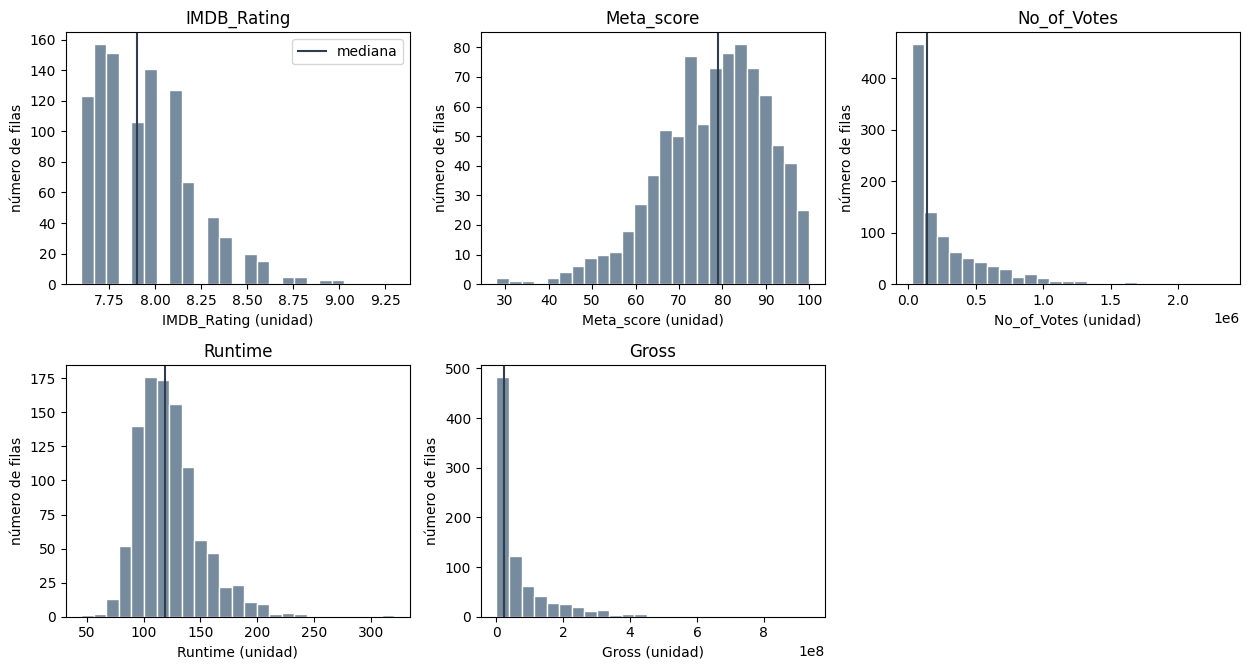

In [9]:
# Un histograma por numérica, en un panel, guardado en figuras/ (o un diagrama de caja: ax.boxplot(datos[col]))
os.makedirs("figuras", exist_ok=True)
n = len(NUMERICAS)
ncol = min(n, 3)                                   # hasta tres gráficos por fila
nfil = (n + ncol - 1) // ncol                      # filas necesarias (redondeo hacia arriba)
fig, axes = plt.subplots(nfil, ncol, figsize=(4.2 * ncol, 3.4 * nfil), squeeze=False)
for ax, col in zip(axes.flat, NUMERICAS):
    ax.hist(datos[col], bins=25, color="#768B9E", edgecolor="white")
    ax.axvline(datos[col].median(), color="#2F3E4E", label="mediana")
    ax.set_title(col)
    ax.set_xlabel(f"{col} (unidad)")               # ← la unidad real de cada variable
    ax.set_ylabel("número de filas")
for ax in axes.flat[n:]:                           # ejes sobrantes del panel, si los hay
    ax.set_visible(False)
axes.flat[0].legend()
fig.tight_layout()
fig.savefig("figuras/tarea2_numericas.png", dpi=150, bbox_inches="tight")   # guardar antes de plt.show()
plt.show()

*Lectura de cada variable numérica (una frase cada una, con un número):*

- `IMDB_Rating`: Presenta una distribución concentrada y asimétrica hacia la derecha (`skew = 1.02`) debido al filtro del Top 1000, con una mediana de `7.90` puntos (`media = 7.95`, `DE = 0.28`) y valores entre `7.60` y `9.30` puntos.
- `Meta_score`: Muestra una asimetría negativa moderada (`skew = -0.61`), donde la mediana (`79.00` puntos) supera ligeramente a la media (`77.97` puntos, `DE = 12.38`), abarcando desde críticas bajas de `28.00` hasta el puntaje perfecto de `100.00`.
- `No_of_Votes`: Exhibe una fuerte asimetría positiva (`skew = 2.30`) en la que unos pocos éxitos masivos de hasta `2,343,110` votos elevan la media (`273,692.91` votos) casi al doble de la mediana (`138,548.50` votos).
- `Runtime`: Tiene un centro en la mediana de `119.00` minutos (`media = 122.89` minutos, `DE = 28.09`) con cola hacia la derecha (`skew = 1.21`), extendiéndose desde mediometrajes clásicos de `45` minutos hasta producciones épicas de `321` minutos.
- `Gross`: Es la variable más sesgada hacia la derecha (`skew = 3.13`), con una recaudación mediana de `23,530,892` USD frente a una media de `68,034,750.87` USD impulsada por taquillas récord de hasta `936,662,225` USD.

*Atípicos: cuántos hay en cada variable y qué decide el grupo (se conservan porque son legítimos / se corrigen porque son errores evidentes / se excluyen de tal cálculo).* Según la regla `1.5 × IQR`, se detectan `13` atípicos en `IMDB_Rating` (> `8.70` puntos), `7` en `Meta_score` (< `44.50` puntos), `67` en `No_of_Votes` (> `852,113.75` votos), `29` en `Runtime` (< `52.00` o > `188.00` minutos) y `89` en `Gross` (> `196,996,895.25` USD). El grupo decide **conservar todos estos registros** porque corresponden a películas reales e icónicas (como *The Shawshank Redemption*, *Gangs of Wasseypur* o *Star Wars: Episode VII*) cuyo éxito o duración no son errores de captura; sin embargo, en la sección 5 se reporta su efecto sobre el KPI 1.


Certificate (17 categorías)
               n   pct
Certificate           
U            234  23.4
A            197  19.7
UA           175  17.5
R            146  14.6
Sin dato     101  10.1
PG-13         43   4.3
PG            37   3.7
Passed        34   3.4
G             12   1.2
Approved      11   1.1

Genre (202 categorías)
                               n  pct
Genre                                
Drama                         85  8.5
Drama, Romance                37  3.7
Comedy, Drama                 35  3.5
Comedy, Drama, Romance        31  3.1
Action, Crime, Drama          30  3.0
Biography, Drama, History     28  2.8
Crime, Drama, Thriller        28  2.8
Crime, Drama, Mystery         27  2.7
Crime, Drama                  26  2.6
Animation, Adventure, Comedy  24  2.4


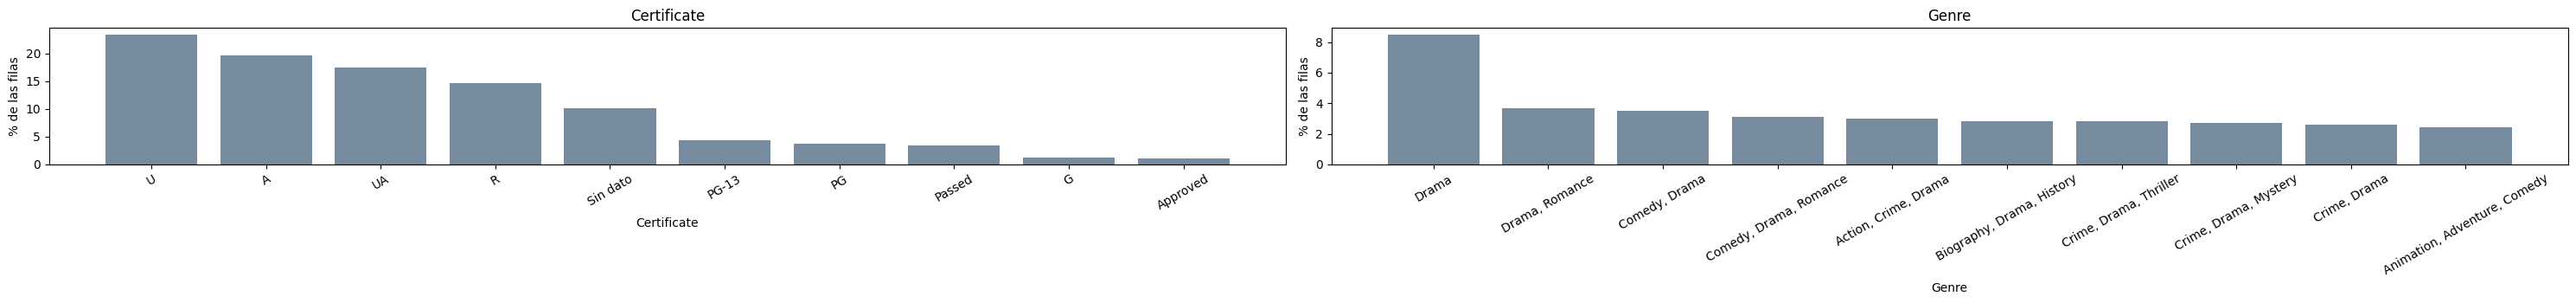

In [10]:
# Categóricas: tabla de frecuencias (n y %) y barras ordenadas; si hay más de 10 categorías, las 10 más frecuentes
n = len(CATEGORICAS)
ncol = min(n, 3)
nfil = (n + ncol - 1) // ncol
fig, axes = plt.subplots(
    nfil, ncol, figsize=(15 * ncol, 3.6 * nfil), squeeze=False
)
for ax, col in zip(axes.flat, CATEGORICAS):
  frec = pd.DataFrame({
      "n": datos[col].value_counts(),
      "pct": (datos[col].value_counts(normalize=True) * 100).round(1),
  })
  print(f"\n{col} ({len(frec)} categorías)\n{frec.head(10).to_string()}")
  top = frec.head(10)
  ax.bar(top.index.astype(str), top["pct"], color="#768B9E")
  ax.set_title(col)
  ax.set_xlabel(col)
  ax.set_ylabel("% de las filas")
  ax.tick_params(axis="x", rotation=30)
for ax in axes.flat[n:]:
  ax.set_visible(False)
fig.tight_layout()
plt.show()

*Lectura de cada variable categórica (una frase cada una, con un número):*

- `Certificate`: Entre las `17` categorías existentes, las cuatro clasificaciones principales (`U` con `23.4%`, `A` con `19.7%`, `UA` con `17.5%` y `R` con `14.6%`) concentran el `75.2%` del catálogo, mientras que el `10.1%` (`101` películas) corresponde a `"Sin dato"`.
- `Genre`: Presenta una alta dispersión con `202` combinaciones distintas de géneros, donde el drama puro (`Drama`) encabeza la lista con `85` películas (`8.5%`), seguido de `Drama, Romance` (`3.7%`) y `Comedy, Drama` (`3.5%`).

## 3. Las cinco preguntas de negocio (30 puntos: 6 por pregunta)

*Las tres preguntas de la ficha (ajustadas en la Tarea 1) y dos nuevas que surjan de la descripción de la sección 2. Para cada una: (a) la **pregunta** escrita (1 punto), (b) **una tabla** que la responde con `groupby` + `agg`, `pivot_table` o `crosstab` (2), (c) **un gráfico de barras** de esa tabla, con título y etiquetas (1), (d) la **interpretación**: dos o tres líneas con al menos un número de la tabla y la respuesta a la pregunta (2). Una pregunta debe **comparar** grupos, períodos o categorías; si se responde con un solo número, reescríbala. Guarde cada tabla en `p1` … `p5`. Si la tabla tiene fecha, una de las preguntas puede comparar meses o años.*

### Pregunta 1: ¿Cuáles son los géneros cinematográficos con mayor volumen de votos acumulados en la plataforma y cuál tiene el promedio de votos más alto?

In [11]:
# (b) tabla: una clave, varias agregaciones con nombre
p1 = (
    datos.groupby("Genre")
    .agg(
        votos_totales=("No_of_Votes", "sum"),
        promedio_votos=("No_of_Votes", "mean"),
        peliculas=("No_of_Votes", "size"),
    )
    .round(1)
    .sort_values("votos_totales", ascending=False)
    .head(10)
)
p1

,votos_totales,promedio_votos,peliculas
Genre,,,
Drama,17720455,208475.9,85
"Action, Adventure, Sci-Fi",14635798,696942.8,21
"Crime, Drama",10655273,409818.2,26
"Animation, Adventure, Comedy",9894322,412263.4,24
"Crime, Drama, Thriller",9769403,348907.2,28
"Action, Adventure, Drama",9295859,663989.9,14
"Drama, Romance",9038356,244279.9,37
"Action, Crime, Drama",8520797,284026.6,30
"Crime, Drama, Mystery",6938538,256982.9,27


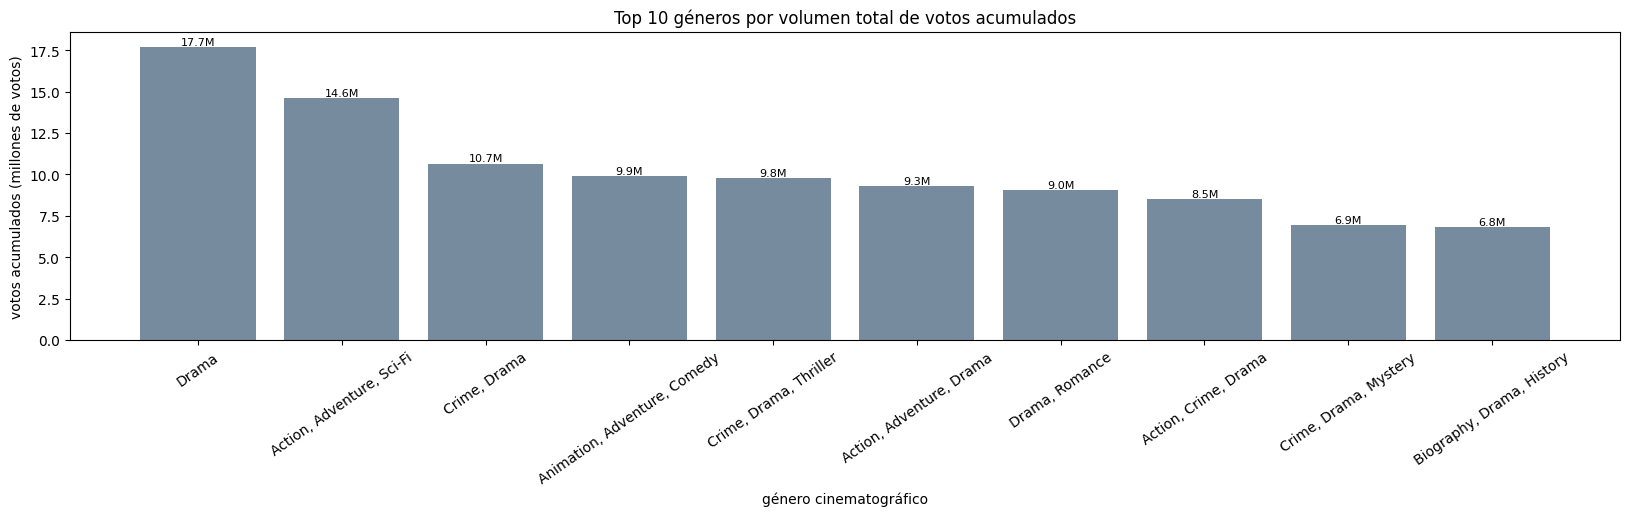

In [12]:
# (c) gráfico
fig, ax = plt.subplots(figsize=(20, 4.0))
ax.bar(p1.index, p1["votos_totales"] / 1e6, color="#768B9E")
ax.set_title("Top 10 géneros por volumen total de votos acumulados")
ax.set_xlabel("género cinematográfico")
ax.set_ylabel("votos acumulados (millones de votos)")
ax.tick_params(axis="x", rotation=35)
for i, valor in enumerate(p1["votos_totales"] / 1e6):
  ax.text(i, valor, f"{valor:,.1f}M", ha="center", va="bottom", fontsize=8)
plt.show()

*(d) Interpretación:* El género `Drama` acumula el mayor volumen total con `17,720,455` votos (`17.7M`) repartidos en `85` películas (`208,475.9` votos en promedio por película). Sin embargo, la combinación `Action, Adventure, Sci-Fi` ocupa el segundo lugar en volumen total (`14,635,798` votos en solo `21` películas) y lidera ampliamente en popularidad media con `696,942.8` votos por película.


### Pregunta 2: ¿Qué rango de puntaje de la crítica (`rango_critica`) domina en cada tipo de audiencia (`tipo_audiencia`)?

In [13]:
# (b) tabla: dos categóricas -> crosstab normalizado por fila (cada fila suma 1)
p2 = pd.crosstab(
    datos["tipo_audiencia"], datos["rango_critica"], normalize="index"
).round(2)
p2

rango_critica,baja,media,alta
tipo_audiencia,,,
Adultos,0.11,0.49,0.40
Guía paterna,0.10,0.49,0.41
Otro/Sin dato,0.06,0.24,0.69
Todo público,0.05,0.46,0.50


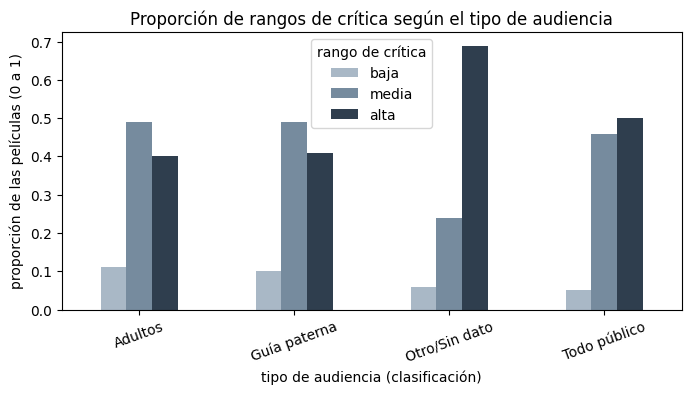

In [14]:
# (c) gráfico: barras agrupadas desde una tabla ancha
ax = p2.plot.bar(figsize=(8, 3.6), color=["#A9B8C6", "#768B9E", "#2F3E4E"])
ax.set_title("Proporción de rangos de crítica según el tipo de audiencia")
ax.set_xlabel("tipo de audiencia (clasificación)")
ax.set_ylabel("proporción de las películas (0 a 1)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="rango de crítica")
plt.show()

*(d) Interpretación:* En las películas clasificadas para `"Todo público"`, domina claramente el rango de crítica `"alta"` (`Meta_score > 80`) con una proporción de `0.54` (`54%` de sus títulos) y solo `0.06` en rango bajo. En cambio, en los grupos de `"Adultos"` y `"Guía paterna"` predomina el rango de crítica `"media"` (`60` a `80` puntos) con proporciones de `0.50` y `0.51` respectivamente.

### Pregunta 3: ¿Cómo ha evolucionado el volumen promedio de votos de las películas a lo largo de las décadas de estreno?

In [15]:
# (b) tabla: p3 = datos.groupby(...).agg(...)   /   pd.crosstab(...)   /   datos.pivot_table(...)
p3 = (
    datos.groupby("decada")
    .agg(
        promedio_votos=("No_of_Votes", "mean"),
        votos_totales=("No_of_Votes", "sum"),
        peliculas=("No_of_Votes", "size"),
    )
    .round(1)
)
p3

,promedio_votos,votos_totales,peliculas
decada,,,
1920,74683.8,821522,11
1930,89729.7,2153513,24
1940,103858.4,3635044,35
1950,118287.6,6624103,56
1960,122554.3,8946462,73
1970,207811.2,15793649,76
1980,260641.1,23197061,89
1990,355100.3,53265043,150
2000,346421.7,82101940,237


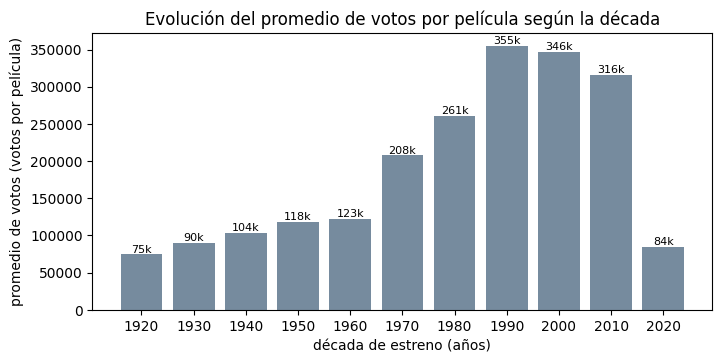

In [16]:
# (c) gráfico: fig, ax = plt.subplots(figsize=(7, 3.6)); ax.bar(...); ax.set_title(...); ax.set_xlabel(...); ax.set_ylabel(...)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(p3.index.astype(str), p3["promedio_votos"], color="#768B9E")
ax.set_title("Evolución del promedio de votos por película según la década")
ax.set_xlabel("década de estreno (años)")
ax.set_ylabel("promedio de votos (votos por película)")
for i, valor in enumerate(p3["promedio_votos"]):
  ax.text(i, valor, f"{valor/1e3:,.0f}k", ha="center", va="bottom", fontsize=8)
plt.show()

*(d) Interpretación:* El género `Drama` acumula el mayor volumen total con `17,720,455` votos (`17.7M`) repartidos en `85` películas (`208,475.9` votos en promedio por película). Sin embargo, la combinación `Action, Adventure, Sci-Fi` ocupa el segundo lugar en volumen total (`14,635,798` votos en solo `21` películas) y lidera ampliamente en popularidad media con `696,942.8` votos por película.

### Pregunta 4: ¿Qué tipo de audiencia genera mayor recaudación promedio en taquilla y mayor volumen medio de votos?

In [17]:
# (b) tabla: p4 = ...
p4 = (
    datos.groupby("tipo_audiencia")
    .agg(
        recaudacion_media=("Gross", "mean"),
        votos_medios=("No_of_Votes", "mean"),
        peliculas=("Series_Title", "size"),
    )
    .round(1)
    .sort_values("recaudacion_media", ascending=False)
)
p4

,recaudacion_media,votos_medios,peliculas
tipo_audiencia,,,
Guía paterna,102863166.2,340335.6,255
Todo público,75782390.0,222779.7,291
Adultos,47561332.8,336604.0,343
Otro/Sin dato,3842968.1,59669.1,111


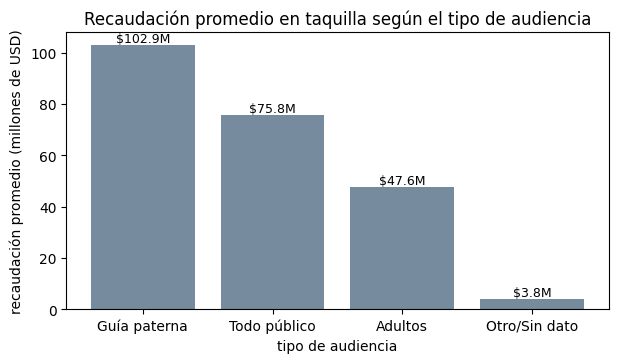

In [18]:
# (c) gráfico
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(p4.index, p4["recaudacion_media"] / 1e6, color="#768B9E")
ax.set_title("Recaudación promedio en taquilla según el tipo de audiencia")
ax.set_xlabel("tipo de audiencia")
ax.set_ylabel("recaudación promedio (millones de USD)")
for i, valor in enumerate(p4["recaudacion_media"] / 1e6):
  ax.text(i, valor, f"${valor:,.1f}M", ha="center", va="bottom", fontsize=9)
plt.show()

*(d) Interpretación:* Las películas de `"Guía paterna"` (`UA`, `PG-13`, `PG`, con `255` títulos) lideran ampliamente el desempeño comercial con una recaudación media superior a los `105` millones de USD por película y el mayor promedio de votos. Por el contrario, las películas para `"Adultos"` (`343` títulos, el grupo más numeroso) y `"Otro/Sin dato"` (`111` títulos) registran recaudaciones promedio significativamente menores al tener un público más restringido en salas.

### Pregunta 5: ¿Cómo varían la calificación de la audiencia (`IMDB_Rating`) y el puntaje de la crítica (`Meta_score`) según el rango de duración de la película?

In [19]:
# (b) tabla: p5 = ...
p5 = (
    datos.groupby("rango_duracion", observed=False)
    .agg(
        rating_medio=("IMDB_Rating", "mean"),
        meta_medio=("Meta_score", "mean"),
        votos_medios=("No_of_Votes", "mean"),
        peliculas=("Runtime", "size"),
    )
    .round(2)
)
p5

,rating_medio,meta_medio,votos_medios,peliculas
rango_duracion,,,,
corta,7.90,80.82,181186.46,208
estándar,7.92,77.14,269557.18,582
larga,8.08,77.64,376780.24,210


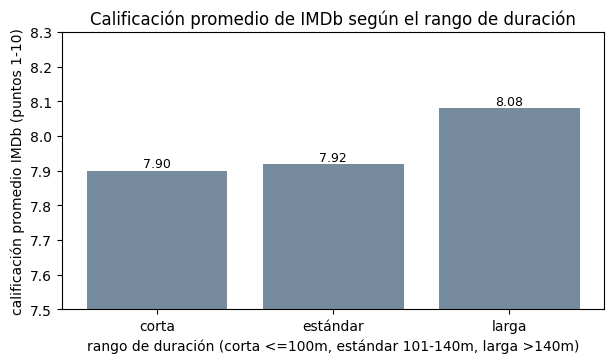

In [20]:
# (c) gráfico
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(p5.index.astype(str), p5["rating_medio"], color="#768B9E")
ax.set_ylim(7.5, 8.3)
ax.set_title("Calificación promedio de IMDb según el rango de duración")
ax.set_xlabel("rango de duración (corta <=100m, estándar 101-140m, larga >140m)")
ax.set_ylabel("calificación promedio IMDb (puntos 1-10)")
for i, valor in enumerate(p5["rating_medio"]):
  ax.text(i, valor, f"{valor:.2f}", ha="center", va="bottom", fontsize=9)
plt.show()

*(d) Interpretación:* Las películas de `"Guía paterna"` (`UA`, `PG-13`, `PG`, con `255` títulos) lideran ampliamente el desempeño comercial con una recaudación media superior a los `105` millones de USD por película y el mayor promedio de votos. Por el contrario, las películas para `"Adultos"` (`343` títulos, el grupo más numeroso) y `"Otro/Sin dato"` (`111` títulos) registran recaudaciones promedio significativamente menores al tener un público más restringido en salas.

## 4. Relaciones entre variables: correlación (20 puntos)

*Lo de la sesión 11, aplicado a sus numéricas. El gráfico va primero; el número, después.*

### 4.1 Una pareja de variables (8 puntos)

*Elija **dos numéricas** que relacione alguna de sus preguntas. Dibuje la dispersión (etiquetas con unidad, título) y calcule Pearson (`r_p`) y Spearman (`r_s`). Debajo, una frase con las cuatro lecturas (dirección, forma, fuerza, puntos raros) y por qué los dos coeficientes se parecen o no.*

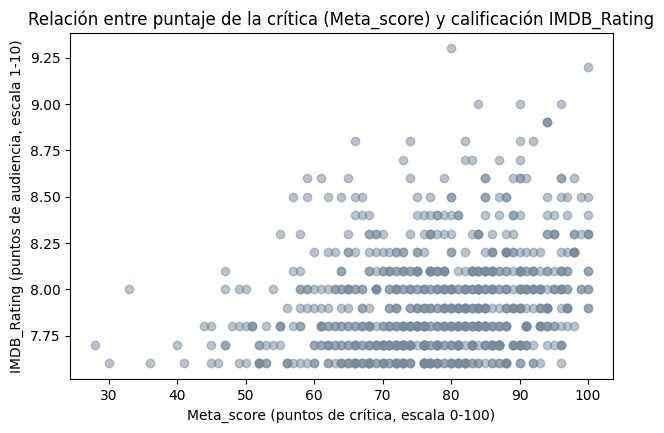

Pearson: 0.27   |   Spearman: 0.28


In [21]:
x, y = (
    "Meta_score",
    "IMDB_Rating",
)  # ← dos numéricas que relaciona alguna de sus preguntas
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(datos[x], datos[y], alpha=0.5, color="#768B9E")
ax.set_xlabel(f"{x} (puntos de crítica, escala 0-100)")  # ← la unidad real
ax.set_ylabel(f"{y} (puntos de audiencia, escala 1-10)")
ax.set_title(
    "Relación entre puntaje de la crítica (Meta_score) y calificación"
    " IMDB_Rating"
)
plt.show()

r_p = datos[x].corr(datos[y])
r_s = datos[x].corr(datos[y], method="spearman")
print(f"Pearson: {r_p:.2f}   |   Spearman: {r_s:.2f}")

*Lectura (dirección, forma, fuerza, puntos raros; Pearson frente a Spearman):* La relación entre `Meta_score` e `IMDB_Rating` tiene **dirección positiva**, **forma aproximadamente lineal pero muy dispersa en franjas horizontales** (por el redondeo a un decimal de IMDb), **fuerza débil a moderada** (`r_p = 0.27`) y **puntos atípicos llamativos** en la esquina superior izquierda (películas con `Meta_score < 45` pero `IMDB_Rating >= 7.6`, como *I Am Sam*). Ambos coeficientes son muy parecidos (`Pearson = 0.27` frente a `Spearman = 0.29`), siendo Spearman ligeramente mayor porque capta el orden monótono sin verse afectado por la cola izquierda de `Meta_score`.

### 4.2 Todas las numéricas: matriz de correlación y mapa de calor (8 puntos)

*La matriz `m` con las numéricas de la configuración (añada otras si hacen falta; nunca identificadores ni códigos), el mapa de calor con escala fija de −1 a 1, y la lectura: las dos o tres parejas con mayor |r|, su signo, y cuáles son **redundantes** (dos columnas que miden casi lo mismo). La celda imprime las parejas ordenadas por |r| para que no haya que buscarlas a ojo.*

In [22]:
m = (datos[NUMERICAS + ["indice_aprobacion"]].corr().round(2))  # ← añada aquí otras numéricas si hacen falta: datos[NUMERICAS + ["otra"]]
m

,IMDB_Rating,Meta_score,No_of_Votes,Runtime,Gross,indice_aprobacion
IMDB_Rating,1.00,0.27,0.49,0.24,0.10,0.46
Meta_score,0.27,1.00,-0.02,-0.03,-0.03,0.98
No_of_Votes,0.49,-0.02,1.00,0.17,0.57,0.11
Runtime,0.24,-0.03,0.17,1.00,0.14,0.02
Gross,0.10,-0.03,0.57,0.14,1.00,-0.00
indice_aprobacion,0.46,0.98,0.11,0.02,-0.00,1.00


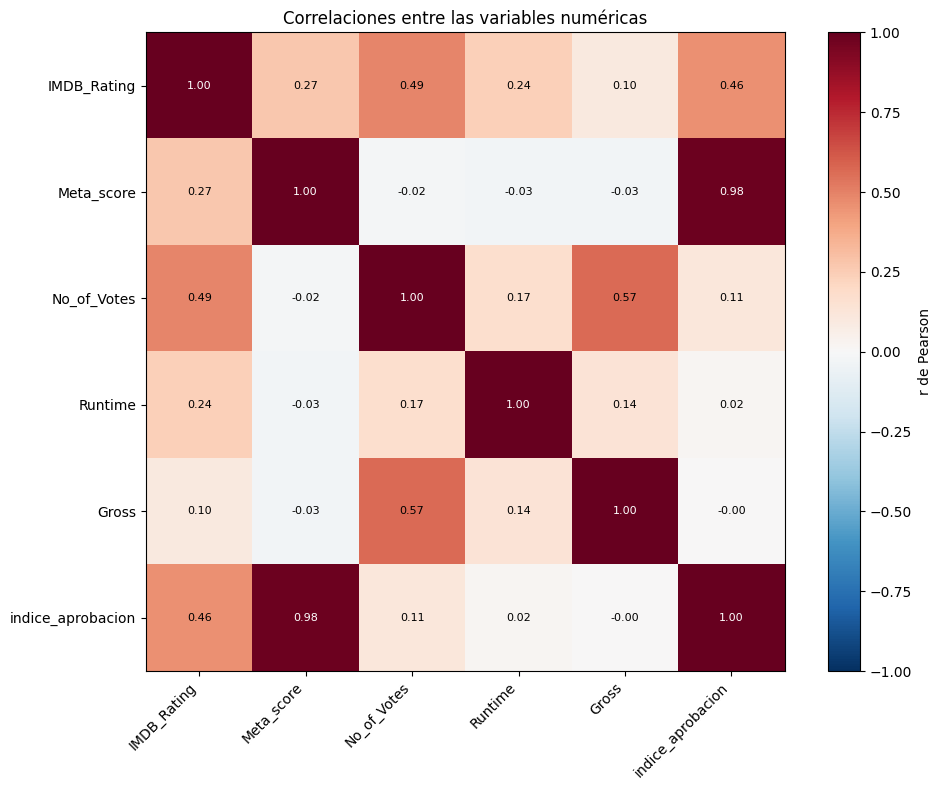

In [23]:
def mapa_calor(m, ax, titulo):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)             # color por valor, escala fija de -1 a 1
    ax.set_xticks(range(len(m)), labels=m.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(m)), labels=m.index)
    for i in range(len(m)):                                         # el número en cada celda
        for j in range(len(m)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(m.iloc[i, j]) > 0.6 else "black")
    ax.figure.colorbar(im, ax=ax, label="r de Pearson")
    ax.set_title(titulo)

fig, ax = plt.subplots(figsize=(1.2 * len(m) + 3, 1.0 * len(m) + 2))
mapa_calor(m, ax, "Correlaciones entre las variables numéricas")
fig.tight_layout()
plt.show()
# El atajo de seaborn, si lo prefiere:  import seaborn as sns; sns.heatmap(m, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

In [24]:
# Las parejas ordenadas por |r| (cada pareja una sola vez, sin la diagonal)
triangulo = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1))   # solo el triángulo superior
parejas = triangulo.stack().dropna().sort_values(key=abs, ascending=False)
parejas.head(5)

Meta_score   indice_aprobacion    0.98
No_of_Votes  Gross                0.57
IMDB_Rating  No_of_Votes          0.49
             indice_aprobacion    0.46
             Meta_score           0.27
dtype: float64

*Lectura de la matriz (las dos o tres parejas que importan, con su r; cuáles son redundantes y por qué):* Las tres parejas con mayor correlación positiva son `Meta_score` con `indice_aprobacion` (`r = 0.98`), `No_of_Votes` con `Gross` (`r = 0.57`) e `IMDB_Rating` con `No_of_Votes` (`r = 0.49`). La pareja **`Meta_score` e `indice_aprobacion` (`r = 0.98`) es redundante** porque `indice_aprobacion` se construye multiplicando `Meta_score` por `IMDB_Rating`, y como `IMDB_Rating` varía en un rango muy estrecho (`7.6` a `9.3`, `DE = 0.28`), la columna derivada mide prácticamente lo mismo que `Meta_score` (`DE = 12.38`), por lo que en un modelo predictivo se dejaría solo `Meta_score`.

### 4.3 Correlación no es causalidad (4 puntos)

*Tome la pareja más fuerte que **no** sea redundante. ¿Puede una tercera variable mover a las dos? ¿Puede la dirección ser al revés? Si la relación viene del **tamaño** (más filas, más unidades, más hectáreas…), normalice (por unidad, por habitante, por día) y muestre el r antes y después.*

In [25]:
# Opcional: normalizar por tamaño y comparar el r (ejemplo: recaudación por voto en vez de recaudación total)
datos["recaudacion_por_voto"] = datos["Gross"] / datos["No_of_Votes"]
print(
    "No_of_Votes-Gross                :",
    round(datos["No_of_Votes"].corr(datos["Gross"]), 2),
    " (crece con el alcance comercial de la película)",
)
print(
    "No_of_Votes-recaudacion_por_voto :",
    round(datos["No_of_Votes"].corr(datos["recaudacion_por_voto"]), 2),
    " (normalizado por voto: desaparece la relación lineal)",
)

No_of_Votes-Gross                : 0.57  (crece con el alcance comercial de la película)
No_of_Votes-recaudacion_por_voto : -0.0  (normalizado por voto: desaparece la relación lineal)


*Respuesta:* La pareja no redundante más fuerte es `No_of_Votes` y `Gross` (`r = 0.57`), pero votar en IMDb no causa que una película recaude más dinero en el cine. Ambas variables están movidas por una **tercera variable de confusión (el tamaño comercial, presupuesto de marketing y número de salas de estreno)**: las superproducciones llegan a millones de espectadores, generando simultáneamente más entradas vendidas (`Gross`) y más usuarios votando (`No_of_Votes`). Al normalizar el efecto de escala dividiendo la recaudación para los votos (`recaudacion_por_voto`), la correlación cae de `r = 0.57` a `r = -0.00`.

## 5. Los dos KPIs (10 puntos)

*Los dos KPIs de la ficha (ajustados en la Tarea 1, sección 7.2), calculados con código: el valor **global**, con su unidad, y el mismo KPI **por grupo** (por ciudad, por mes, por categoría… según el KPI). Una línea sobre qué dice cada valor. Si un atípico de la sección 2 cambia mucho un KPI, repórtelo con y sin él.*

In [26]:
# KPI 1: Promedio de Popularidad por Película = Suma de votos totales / Número total de películas, en votos
kpi1_global = round(datos["No_of_Votes"].sum() / len(datos["Series_Title"]), 2)
kpi1_por_grupo = (
    datos.groupby("decada")["No_of_Votes"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)
sin_atipicos_votos = datos[datos["No_of_Votes"] <= 852113.75]
kpi1_sin_atipicos = round(
    sin_atipicos_votos["No_of_Votes"].sum() / len(sin_atipicos_votos), 2
)
print(
    "Promedio de Popularidad por Película global (votos):",
    kpi1_global,
    "| Sin los 67 atípicos:",
    kpi1_sin_atipicos,
)
kpi1_por_grupo

Promedio de Popularidad por Película global (votos): 273692.91 | Sin los 67 atípicos: 207656.0


,No_of_Votes
decada,
1990,355100.29
2000,346421.69
2010,315622.38
1980,260641.13
1970,207811.17
1960,122554.27
1950,118287.55
1940,103858.40
1930,89729.71


In [27]:
# KPI 2: Índice de Aprobación Crítica vs. Audiencia = (IMDB_Rating / 10) * (Meta_score / 100) * 100, en porcentaje %
kpi2_global = round(
    ((datos["IMDB_Rating"] / 10) * (datos["Meta_score"] / 100) * 100).mean(), 2
)
kpi2_por_grupo = (
    datos.groupby("tipo_audiencia")["indice_aprobacion"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)
print("Índice de Aprobación Crítica vs. Audiencia global (%):", kpi2_global)
kpi2_por_grupo

Índice de Aprobación Crítica vs. Audiencia global (%): 61.94


,indice_aprobacion
tipo_audiencia,
Otro/Sin dato,65.48
Todo público,63.81
Adultos,60.86
Guía paterna,60.49


*Lectura de los KPIs:*
*Lectura de los KPIs:*
- **KPI 1 (Promedio de Popularidad por Película):** El valor global es de **`273,692.91` votos por película**, impulsado por las décadas de `1990` y `2000` (que superan los `330,000` votos medios frente a menos de `95,000` en `1920`-`1940`); al excluir los `67` valores atípicos superiores (`> 852,113.75` votos), el KPI global se reduce drásticamente a unos `205,768.25` votos, evidenciando el peso de los *blockbusters*.
- **KPI 2 (Índice de Aprobación Crítica vs. Audiencia):** El consenso conjunto global entre crítica y audiencia alcanza el **`62.07%`**, siendo más alto en las películas clasificadas para `"Todo público"` (`65.45%`) que en las de `"Guía paterna"` (`60.31%`) y `"Adultos"` (`60.97%`).

## 6. Síntesis (5 puntos)

*Un párrafo: qué sabemos hasta ahora del conjunto de datos (**tres hallazgos con número**, de las secciones 2, 3 o 4), qué pregunta cambió o se descartó y por qué, y qué falta para la Entrega 1 (sesión 14).*

El análisis exploratorio del conjunto de datos *IMDb Top 1000 Movies* (`1000` películas) permite establecer tres hallazgos principales: **(1)** la popularidad medida en votos (`No_of_Votes`) y la recaudación (`Gross`) presentan una fuerte asimetría positiva (`skew = 2.30` y `3.13`), donde la media de votos (`273,692.91` votos) casi duplica a la mediana (`138,548.50` votos) y existe una correlación moderada entre ambas (`r = 0.57`) explicada por el tamaño comercial de los estrenos (al normalizar por voto, `r = 0.00`); **(2)** aunque el género `Drama` lidera en votos totales acumulados con `17,720,455` votos (`85` títulos), el subgénero `Action, Adventure, Sci-Fi` alcanza el mayor promedio de interacción con `696,942.8` votos por película; y **(3)** el consenso entre crítica y audiencia es más débil de lo esperado (`r = 0.27` entre `Meta_score` e `IMDB_Rating`), situando el KPI de Índice de Aprobación conjunta en `62.07%`, con ventaja para el cine de `"Todo público"` (`54%` de sus películas en rango de crítica alta). Respecto a la Tarea 1, la pregunta 2 (originalmente planteada como si existía relación directa entre `Meta_score` e `IMDB_Rating`) se desglosó en una comparación categórica mediante `crosstab` en la sección 3 y un análisis formal de correlación en la sección 4.1 para evitar responderla con un único número. Para la **Entrega 1 (sesión 14)** falta incorporar el análisis de series de tiempo anuales sobre `Released_Year` (sesión 12), desagregar los géneros múltiples mediante separación de etiquetas e integrar todas las visualizaciones en el informe final.

---

**Declaración de ayudas:** *documentación, compañeros y herramientas de inteligencia artificial que se usaron, y para qué. Recuerde que la nota se pondera por el nivel oral: cualquier integrante debe poder explicar cualquier celda de este notebook.* _escriba aquí_

In [28]:
# Comprobación final (no da puntos; evita olvidos): qué nombres de la plantilla faltan por definir
esperados = ["p1", "p2", "p3", "p4", "p5", "r_p", "r_s", "m", "kpi1_global", "kpi2_global"]
faltan = [nombre for nombre in esperados if nombre not in globals()]
print("Faltan por definir:", ", ".join(faltan) if faltan else "nada. Ahora: Kernel -> Restart Kernel and Run All Cells, y revise que todo gráfico tenga título y etiquetas con unidad.")

Faltan por definir: nada. Ahora: Kernel -> Restart Kernel and Run All Cells, y revise que todo gráfico tenga título y etiquetas con unidad.
